# 02 · Search spaces, decoder and shared starts (Methods 3.2, 3.4.2, 3.5)
All five methods search the same unit box [0,1]^d; one decoder turns a point into model settings.

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import display
from hpo import config, data, spaces, starts, methods, runner, stats, plots

pd.set_option("display.precision", 5)
# Results folder: the full run by default. Set HPO_RESULTS=smoke to read the smoke test.
RESULTS = (
    config.SMOKE_DIR if os.environ.get("HPO_RESULTS") == "smoke" else config.RESULTS_DIR
)
FIGS, TABLES = RESULTS / "figures", RESULTS / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
print("Reading/writing:", RESULTS.relative_to(config.ROOT))

Reading/writing: results


## Table 2 · GA, DE and PSO settings (Methods 3.3; fixed before any run)

In [2]:
settings = pd.DataFrame(
    [
        {
            "method": k.upper(),
            "update rule": v["rule"],
            "settings": ", ".join(
                f"{ {'wf': 'F', 'cr': 'CR'}.get(p, p)}={x}"
                for p, x in v["params"].items()
            ),
            "population x rounds": f"{config.POP_SIZE} x (1 + {config.EPOCHS})",
        }
        for k, v in config.METAHEURISTICS.items()
    ]
)
settings.to_csv(TABLES / "table2_settings.csv", index=False)
settings

,method,update rule,settings,population x rounds
0,GA,"generational, 1 elite; tournament k=3; uniform...","pc=0.95, pm=0.1, k=3",16 x (1 + 15)
1,DE,DE/rand/1/bin with j_rand; synchronous replace...,"F=0.5, CR=0.9",16 x (1 + 15)
2,PSO,global best; own best per particle; v0 = 0; ha...,"w=0.729844, c1=1.49618, c2=1.49618",16 x (1 + 15)


## Table A1 · Search-space bounds (Appendix A)

In [3]:
bounds = pd.DataFrame([r for m in config.MODELS for r in spaces.bounds_table(m)])
bounds.to_csv(TABLES / "tableA1_bounds.csv", index=False)
bounds

,model,setting,range,scale
0,svm,C,2^-5 – 2^15,log2
1,svm,gamma,2^-15 – 2^3,log2
2,rf,n_estimators,50 – 500,int
3,rf,max_depth,3 – 30,int
4,rf,min_samples_split,2 – 20,int
5,rf,max_features,0.1 – 1.0,float
6,xgb,learning_rate,2^-10 – 2^0,log2
7,xgb,n_estimators,50 – 1000,int
8,xgb,subsample,0.1 – 1.0,float
9,xgb,max_depth,1 – 15,int


## Decoder example: the middle of the box

In [4]:
for m in config.MODELS:
    print(m, spaces.decode(m, [0.5] * spaces.dims(m)))

svm {'C': 32.0, 'gamma': 0.015625}
rf {'n_estimators': 275, 'max_depth': 17, 'min_samples_split': 11, 'max_features': 0.55}
xgb {'learning_rate': 0.03125, 'n_estimators': 525, 'subsample': 0.55, 'max_depth': 8, 'colsample_bytree': 0.55}


## Grid values (cell centres) and the 256-point check

In [5]:
for m in config.MODELS:
    U = spaces.grid_unit_points(m)
    uniq = {tuple(sorted(spaces.decode(m, u).items())) for u in U}
    print(
        f"{m}: {config.GRID_LEVELS[m]} -> {len(U)} points, {len(uniq)} unique settings"
    )
    for k, v in spaces.grid_values(m).items():
        print(f"    {k:<18}", [round(x, 4) if isinstance(x, float) else x for x in v])

svm: [16, 16] -> 256 points, 256 unique settings
    C                  [0.0482, 0.1146, 0.2726, 0.6484, 1.5422, 3.668, 8.7241, 20.7494, 49.3507, 117.3765, 279.17, 663.9819, 1579.2239, 3756.0486, 8933.4393, 21247.4193]
    gamma              [0.0, 0.0001, 0.0002, 0.0005, 0.001, 0.0022, 0.0049, 0.0106, 0.0231, 0.0503, 0.1098, 0.2394, 0.5221, 1.1388, 2.4837, 5.417]
rf: [4, 4, 4, 4] -> 256 points, 256 unique settings
    n_estimators       [106, 219, 331, 444]
    max_depth          [6, 13, 20, 27]
    min_samples_split  [4, 9, 13, 18]
    max_features       [0.2125, 0.4375, 0.6625, 0.8875]
xgb: [4, 4, 4, 2, 2] -> 256 points, 256 unique settings
    learning_rate      [0.0023, 0.0131, 0.0743, 0.4204]
    n_estimators       [169, 406, 644, 881]
    subsample          [0.2125, 0.4375, 0.6625, 0.8875]
    max_depth          [5, 12]
    colsample_bytree   [0.325, 0.775]


## Grid vs Random with the same 256 fits (why random search is a strong baseline)

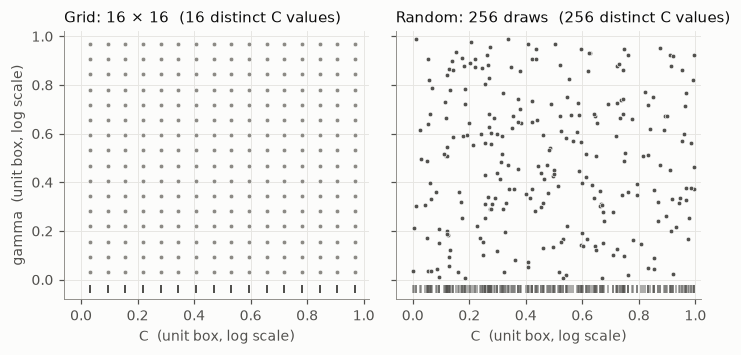

In [6]:
fig = plots.fig_coverage_2d(seed=0)
plots.save(fig, FIGS, "nb02_grid_vs_random_coverage")

## Shared starts: seed 3 gives the same 16 points to Random, GA, DE and PSO

In [7]:
pd.DataFrame(
    starts.shared_starts(3, spaces.dims("rf")),
    columns=[s["name"] for s in config.SPACES["rf"]],
).round(3)

,n_estimators,max_depth,min_samples_split,max_features
0,0.541,0.379,0.900,0.617
1,0.239,0.381,0.298,0.514
2,0.688,0.862,0.908,0.213
3,0.645,0.147,0.169,0.641
4,0.480,0.213,0.442,0.054
5,0.399,0.107,0.601,0.355
6,0.690,0.331,0.787,0.843
7,0.946,0.753,0.493,0.230
8,0.978,0.507,0.773,0.070
9,0.383,0.988,0.710,0.149
